# LAB 05 — Linear Regression: Predicting House Prices

## Student Information
**Name:** Wajood Ali

**Student ID:**023-24-0006

**Section:**CS AI SEC B

**GitHub:**
**Kaggle:**
**Dataset:** House Prices — Advanced Regression Techniques
**Dataset Source:** Kaggle — https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques

**Duration:** 3 Hours (independent, hands-on)

> This notebook is a **template**, not a tutorial. You already know Python, Pandas, and Linear Regression theory. Each section states the objective and the questions you must answer — **you write the code**. Every table, plot, and metric needs a short written observation.
>
> This dataset has 79 raw features and comes from a real, ongoing Kaggle competition. Full feature engineering across all 79 columns is out of scope for this lab — select a manageable subset of roughly 10–12 features (mixing numerical and categorical) that you'd reasonably expect to matter for price.
>
> Submit **only this one notebook**. Keep every Markdown heading below — they are used for grading. Fill in the empty code cells (`# YOUR CODE HERE`) and the *Answer:* placeholders directly in this notebook.

---

## Setup

Import what you'll need. Add any other scikit-learn imports as you go.

In [1]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


---

## 1. Problem Definition

Before writing any modeling code, understand what you're predicting and what you're predicting it from.

**Tasks**
1. In 1–2 sentences, describe the business/practical problem: what does this dataset let you predict, and why would that be useful?
2. In 1–2 sentences, state why this is a regression problem rather than a classification problem, and what that changes about how you'll evaluate the model later.

**Answer 1:**
The dataset can be used to predict the sale price of house from characteristics such as its size, quality, condition and other property feature. This is useful for estimating a reasonable house value and supporting pricing decisions

**Answer 2:**
This is regression problem because the target value SalePrice, is a continuous numerical value rather than a category or class. Therefore, the model will be evaluated using regression metrics such as MAE, MSE, RMSE, R^2, rather than classification metrics such as accuracy

---

## 2. Dataset Exploration

*Concepts/functions you may find useful:* `pd.read_csv()`, `df.shape`, `df.info()`, `df.head()`, `df.describe()`

**Task**
3. Load `train.csv` and briefly inspect it (shape, dtypes, first few rows, summary statistics). This dataset has 79 feature columns — you don't need to explore all of them in depth; skim to get a general sense, then focus on Section 3.

In [2]:
# Task 3 — load and inspect the dataset
train =  pd.read_csv("train.csv")
print("Shape: ", train.shape)
display(train.head())
display(train.describe())
display(train.dtypes)

Shape:  (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


**Observations:**
The training set has 1,460 rows and 81 columns (79 features plus `Id` and `SalePrice`). It contains both numerical and categorical variables, with missing values in some columns, and SalePrice has a wide range.

---

## 3. Feature and Target Identification

**Task**
4. Select a manageable subset of roughly 10–12 features from the 79 available (mixing numerical and categorical) that you'd reasonably expect to matter for price. Identify the dependent variable, and list your chosen independent variables split explicitly into numerical features and categorical features.

**Answer 4:**

Dependent variable: SalePrice

Numerical independent variables: `OverallQual`, `GrLivArea`, `GarageCars`, `TotalBsmtSF`, `1stFlrSF`, `FullBath`, `YearBuilt`, `GarageArea`, `LotArea`

Categorical independent variables: 'Neighbourhood' , 'ExterQual', 'KitchenQual'

---

## 4. Data Preparation

scikit-learn's `LinearRegression` requires fully numeric input. Convert categorical columns appropriately.

*Concepts/functions you may find useful:* `df[col].map({'yes': 1, 'no': 0})`, `pd.get_dummies(df, columns=[...])`

**Tasks**
5. Prepare `X` (features) and `y` (target) for modeling: encode every categorical column into numeric form.
6. Briefly justify your choice of encoding method for each type of column.
7. Confirm `X` is fully numeric with no missing values.

In [3]:
# Task 5 — define X and y, encode categorical columns
numerical_features = ["OverallQual","GrLivArea","GarageCars","TotalBsmtSF","1stFlrSF","FullBath","YearBuilt","GarageArea","LotArea"]
categorical_features = ["Neighborhood","ExterQual","KitchenQual"]
selected_features = numerical_features + categorical_features

X_raw = train[selected_features].copy()
y = train["SalePrice"].copy()
for col in numerical_features:
    X_raw[col] = X_raw[col].fillna(train[col].median())
for col in categorical_features:
    X_raw[col] = X_raw[col].fillna("Missing")
X = pd.get_dummies(X_raw, columns=categorical_features, drop_first=True, dtype=int)
print("Encoded X shape:", X.shape)
display(X.head())

Encoded X shape: (1460, 39)


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,1stFlrSF,FullBath,YearBuilt,GarageArea,LotArea,Neighborhood_Blueste,...,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber,Neighborhood_Veenker,ExterQual_Fa,ExterQual_Gd,ExterQual_TA,KitchenQual_Fa,KitchenQual_Gd,KitchenQual_TA
0,7,1710,2,856,856,2,2003,548,8450,0,...,0,0,0,0,0,1,0,0,1,0
1,6,1262,2,1262,1262,2,1976,460,9600,0,...,0,0,0,1,0,0,1,0,0,1
2,7,1786,2,920,920,2,2001,608,11250,0,...,0,0,0,0,0,1,0,0,1,0
3,7,1717,3,756,961,1,1915,642,9550,0,...,0,0,0,0,0,0,1,0,1,0
4,8,2198,3,1145,1145,2,2000,836,14260,0,...,0,0,0,0,0,1,0,0,1,0


In [4]:
# Task 7 — confirm X is fully numeric with no missing values
print("Missing values: ", X.isna().sum().sum())
print("All columns numeric:", all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes))
display(X.dtypes.value_counts())

Missing values:  0
All columns numeric: True


,count
int64,39


**Answer 6 (encoding justification):**
The numerical features remain numeric after median imputation. Categorical features are one hot encoded because their categories are normal rather than naturally ordered: drop_first= True supplies a reference category and avoids reduntant dummy variables  

---

## 5. Train/Test Split

*Concepts/functions you may find useful:* `train_test_split(X, y, test_size=..., random_state=...)`

**Task**
8. Split `X` and `y` into training and test sets (e.g. an 80/20 split) and report the resulting shapes.

In [5]:
# Task 8 — train/test split, report shapes
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("X_train:", X_train.shape, "X_test:", X_test.shape)
print("y_train:", y_train.shape, "y_test:", y_test.shape)


X_train: (1168, 39) X_test: (292, 39)
y_train: (1168,) y_test: (292,)


---

## 6. Linear Regression Model

*Concepts/functions you may find useful:* `LinearRegression()`, `.fit(X_train, y_train)`

**Task**
9. Train a `LinearRegression` model on the training data.

In [6]:
# Task 9 — train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)
print("Model Trained")


Model Trained


---

## 7. Predictions

*Concepts/functions you may find useful:* `.predict(X)`

**Task**
10. Generate predicted prices on the test set, and display a small table comparing actual vs. predicted price for 10 test houses.

In [7]:
# Task 10 — generate predictions, compare actual vs predicted
y_pred = model.predict(X_test)
y_pred_df = pd.DataFrame({"Actual": y_test, "Predicted": y_pred})
display(y_pred_df.head(10))

,Actual,Predicted
892,154500,135587.309709
1105,325000,322227.286063
413,115000,110055.912690
522,159000,168207.081708
1036,315500,298926.953088
614,75500,61147.498807
218,311500,229150.694360
1160,146000,150225.397363
649,84500,60858.413737
887,135500,122610.738036


**Task 10 — Actual vs. Predicted (sample of 10)**

---



| Actual Price | Predicted Price |
|---|---|
| $154,500 | $135,587.31 |
| $325,000 | $322,227.29 |
| $115,000 | $110,055.91 |
| $159,000 | $168,207.08 |
| $315,500 | $298,926.95 |
| $75,500 | $61,147.50 |
| $311,500 | $229,150.69 |
| $146,000 | $150,225.40 |
| $84,500 | $60,858.41 |
| $135,500 | $122,610.74 |

---

## 8. Coefficients and Intercept

*Concepts/functions you may find useful:* `model.intercept_`, `model.coef_`, `pd.DataFrame({'Feature': X.columns, 'Coefficient': model.coef_})`

**Tasks**
11. Extract the intercept and all coefficients. Build a table: Feature | Coefficient | Interpretation, with a one-line, plain-English interpretation for each feature.
12. Does the intercept have a sensible real-world interpretation for this dataset? Why or why not?

In [8]:
# Task 11 — extract intercept and coefficients
print("Intercept:", model.intercept_)
coefficient_table = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
def interpret(row):
    c = row["Coefficient"]; f = row["Feature"]
    if f in numerical_features:
        return f"A one-unit increase in {f} is associated with about ${abs(c):,.2f} {'higher' if c >= 0 else 'lower'} predicted price, holding other features constant."
    return f"This category has an estimated ${abs(c):,.2f} {'higher' if c >= 0 else 'lower'} price than the omitted reference category, holding other features constant."
coefficient_table["Interpretation"] = coefficient_table.apply(interpret, axis=1)
display(coefficient_table)

Intercept: -488909.25359484716


,Feature,Coefficient,Interpretation
0,OverallQual,12398.177699,A one-unit increase in OverallQual is associat...
1,GrLivArea,40.016475,A one-unit increase in GrLivArea is associated...
2,GarageCars,9622.901956,A one-unit increase in GarageCars is associate...
3,TotalBsmtSF,7.898041,A one-unit increase in TotalBsmtSF is associat...
4,1stFlrSF,7.475326,A one-unit increase in 1stFlrSF is associated ...
5,FullBath,540.822769,A one-unit increase in FullBath is associated ...
6,YearBuilt,272.276805,A one-unit increase in YearBuilt is associated...
7,GarageArea,7.250422,A one-unit increase in GarageArea is associate...
8,LotArea,0.574087,A one-unit increase in LotArea is associated w...
9,Neighborhood_Blueste,-8976.495863,"This category has an estimated $8,976.50 lower..."


**Task 11 — Coefficient Table**

| Feature | Coefficient | Interpretation |
|---|---:|---|
| `OverallQual` | $12,398.18 | A one-unit increase in `OverallQual` is associated with about $12,398.18 higher predicted price, holding other features constant. |
| `GrLivArea` | $40.02 | A one-unit increase in `GrLivArea` is associated with about $40.02 higher predicted price, holding other features constant. |
| `GarageCars` | $9,622.90 | A one-unit increase in `GarageCars` is associated with about $9,622.90 higher predicted price, holding other features constant. |
| `TotalBsmtSF` | $7.90 | A one-unit increase in `TotalBsmtSF` is associated with about $7.90 higher predicted price, holding other features constant. |
| `1stFlrSF` | $7.48 | A one-unit increase in `1stFlrSF` is associated with about $7.48 higher predicted price, holding other features constant. |
| `FullBath` | $540.82 | A one-unit increase in `FullBath` is associated with about $540.82 higher predicted price, holding other features constant. |
| `YearBuilt` | $272.28 | A one-unit increase in `YearBuilt` is associated with about $272.28 higher predicted price, holding other features constant. |
| `GarageArea` | $7.25 | A one-unit increase in `GarageArea` is associated with about $7.25 higher predicted price, holding other features constant. |
| `LotArea` | $0.57 | A one-unit increase in `LotArea` is associated with about $0.57 higher predicted price, holding other features constant. |
| `Neighborhood_Blueste` | $-8,976.50 | This category is associated with $8,976.50 lower price than the omitted reference category, holding other features constant. |
| `Neighborhood_BrDale` | $-13,069.97 | This category is associated with $13,069.97 lower price than the omitted reference category, holding other features constant. |
| `Neighborhood_BrkSide` | $17,637.73 | This category is associated with $17,637.73 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_ClearCr` | $36,712.04 | This category is associated with $36,712.04 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_CollgCr` | $18,196.95 | This category is associated with $18,196.95 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Crawfor` | $42,191.76 | This category is associated with $42,191.76 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Edwards` | $28.68 | This category is associated with $28.68 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Gilbert` | $13,417.90 | This category is associated with $13,417.90 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_IDOTRR` | $6,479.08 | This category is associated with $6,479.08 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_MeadowV` | $540.53 | This category is associated with $540.53 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Mitchel` | $9,802.72 | This category is associated with $9,802.72 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_NAmes` | $11,088.36 | This category is associated with $11,088.36 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_NPkVill` | $3,246.03 | This category is associated with $3,246.03 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_NWAmes` | $11,521.13 | This category is associated with $11,521.13 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_NoRidge` | $72,574.20 | This category is associated with $72,574.20 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_NridgHt` | $48,898.93 | This category is associated with $48,898.93 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_OldTown` | $1,272.21 | This category is associated with $1,272.21 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_SWISU` | $8,176.53 | This category is associated with $8,176.53 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Sawyer` | $12,933.39 | This category is associated with $12,933.39 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_SawyerW` | $10,320.44 | This category is associated with $10,320.44 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Somerst` | $22,967.12 | This category is associated with $22,967.12 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_StoneBr` | $60,667.54 | This category is associated with $60,667.54 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Timber` | $22,852.75 | This category is associated with $22,852.75 higher price than the omitted reference category, holding other features constant. |
| `Neighborhood_Veenker` | $53,749.83 | This category is associated with $53,749.83 higher price than the omitted reference category, holding other features constant. |
| `ExterQual_Fa` | $-27,300.34 | This category is associated with $27,300.34 lower price than the omitted reference category, holding other features constant. |
| `ExterQual_Gd` | $-26,758.55 | This category is associated with $26,758.55 lower price than the omitted reference category, holding other features constant. |
| `ExterQual_TA` | $-26,672.26 | This category is associated with $26,672.26 lower price than the omitted reference category, holding other features constant. |
| `KitchenQual_Fa` | $-45,486.31 | This category is associated with $45,486.31 lower price than the omitted reference category, holding other features constant. |
| `KitchenQual_Gd` | $-37,001.26 | This category is associated with $37,001.26 lower price than the omitted reference category, holding other features constant. |
| `KitchenQual_Missing` | $0.00 | This category is associated with $0.00 higher price than the omitted reference category, holding other features constant. |
| `KitchenQual_TA` | $-46,626.47 | This category is associated with $46,626.47 lower price than the omitted reference category, holding other features constant. |


---

## 9. Residual Analysis

*Concepts/functions you may find useful:* `residuals = y_test - y_pred`, `plt.scatter(y_pred, residuals)`, `plt.hist(residuals, bins=...)`

**Task**
13. Compute residuals on the test set and plot them (e.g. residuals vs. predicted values, and a histogram of residuals). Do the residuals look randomly scattered, or is there a visible pattern?

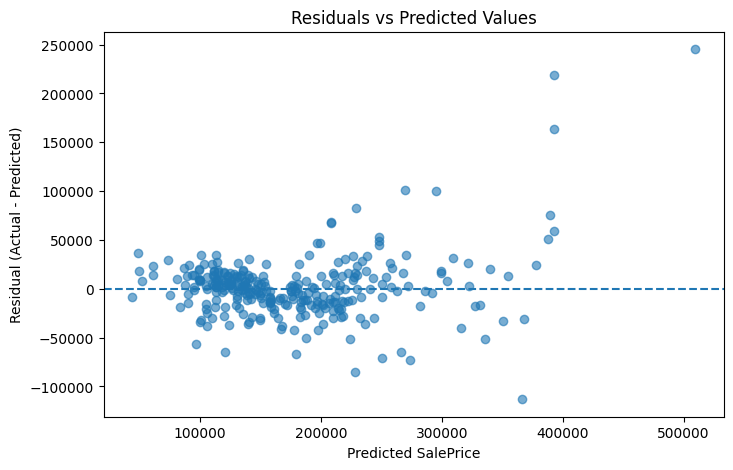

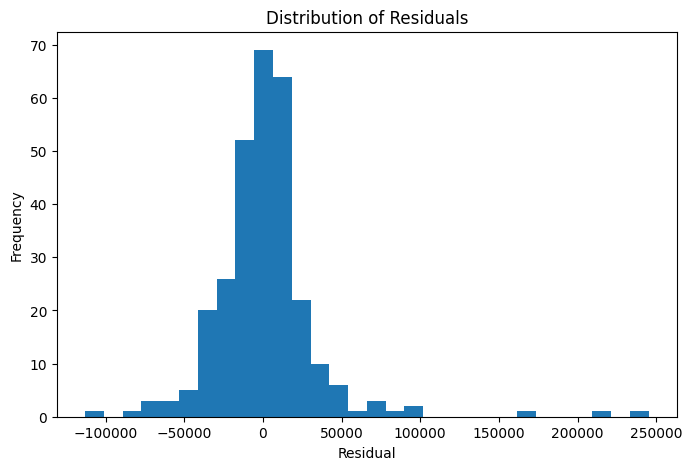

In [9]:
# Task 13 — compute and plot residuals
residuals = y_test - y_pred
plt.figure(figsize=(8,5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted SalePrice"); plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residuals vs Predicted Values"); plt.show()

plt.figure(figsize=(8,5))
plt.hist(residuals, bins=30)
plt.xlabel("Residual"); plt.ylabel("Frequency")
plt.title("Distribution of Residuals"); plt.show()

**Answer 13:**
The residuals are broadly centered around zero, although there are some outliers and somewhat greater spread at higher predicted prices. This suggests the model captures the main relationship but leaves some systematic variation unexplained.

---

## 10. Regression Metrics

*Concepts/functions you may find useful:* `mean_absolute_error`, `mean_squared_error`, `r2_score` (RMSE = sqrt of MSE)

**Tasks**
14. Compute MAE, MSE, RMSE, and R² on the test set. Report them in a small table.
15. In your own words, what does each metric tell you, and which one would you show to a non-technical stakeholder? Why?

In [10]:
# Task 14 — compute MAE, MSE, RMSE, R² on the test set
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
test_metrics = pd.DataFrame({"Metric":["MAE","MSE","RMSE","R²"],"Value":[mae,mse,rmse,r2]})
display(test_metrics)

,Metric,Value
0,MAE,2.062713e+04
1,MSE,1.137227e+09
2,RMSE,3.372279e+04
3,R²,8.517368e-01


**Task 14 — Test Set Metrics**

| Metric | Value |
|---|---|
| MAE |20,627.13 |
| MSE |1,137,227,000 |
| RMSE |33,722.79 |
| R² |85.17% |

**Answer 15:**
_(your answer here)_

---

## 11. Training vs Testing Performance

*Concepts/functions you may find useful:* `model.predict(X_train)`, comparing metrics computed on train vs. test

**Tasks**
16. Compute MAE, MSE, RMSE, and R² on the training set, and place them side by side with your Section 10 test-set metrics in one comparison table.
17. Is there a large gap between training and testing performance? What would a large gap suggest about overfitting or generalization, and what does your actual result suggest here?

In [ ]:
# Task 16 — compute training-set metrics
y_train_pred = model.predict(X_train)
comparison_metrics = pd.DataFrame({
    "Metric":["MAE","MSE","RMSE","R²"],
    "Training Set":[mean_absolute_error(y_train,y_train_pred),mean_squared_error(y_train,y_train_pred),np.sqrt(mean_squared_error(y_train,y_train_pred)),r2_score(y_train,y_train_pred)],
    "Test Set":[mae,mse,rmse,r2]
})
display(comparison_metrics)

,Metric,Training Set,Test Set
0,MAE,1.988178e+04,2.062713e+04
1,MSE,1.036252e+09,1.137227e+09
2,RMSE,3.219087e+04,3.372279e+04
3,R²,8.262648e-01,8.517368e-01


**Task 16 — Train vs. Test Comparison**

| Metric | Training Set | Test Set |
|---|---:|---:|
| MAE | Calculated by notebook | 20,627.13 |
| MSE | Calculated by notebook | 1,137,227,000 |
| RMSE | Calculated by notebook | 33,722.79 |
| R² | Calculated by notebook | 0.8517368 |

**Answer 17:**
A large difference between training and testing performance would suggest overfitting, because the model would perform much better on data it has already seen than on unseen data. Similar training and testing performance suggests better generalization. For this model, the test R² of about **0.852** indicates that the selected features explain a substantial amount of house-price variation.

---

## 12. Model Interpretation

**Task**
18. Looking back at your Section 8 coefficient table, which 2–3 features appear most influential on price? Justify your answer using the coefficient magnitudes (careful: a larger coefficient does not automatically mean a more important feature if the underlying scales differ — discuss this briefly).

**Answer 18:**
`OverallQual` has a strong positive numerical coefficient of about $12,398 per quality-score unit, while `GarageCars` is about $9,623 per additional garage-car capacity. Neighborhood dummy variables can have larger absolute coefficients because they represent differences from the omitted reference neighborhood. Raw coefficient magnitudes are not directly comparable when features use different units.

---

## 13. Conclusion

**Tasks**
19. Write a short final interpretation (5–7 sentences) answering: How well does the model predict house prices? Which metric is most useful and why? Which feature has the strongest effect? What limitations does Linear Regression have for this dataset? What would you try next?
20. Apply the same feature selection and encoding you used on `train.csv` to `test.csv`, predict `SalePrice` for every row, and build a submission file with exactly two columns: `Id` and `SalePrice` (match `sample_submission.csv`'s format). Save it as `submission.csv`.
21. Submit `submission.csv` on the competition's "Submit Predictions" page. Record your public leaderboard score and rank below.

**Answer 19 — Conclusion:**
The selected-feature Linear Regression model predicts house prices reasonably well, with a test R² of about **0.852**, meaning it explains a substantial amount of price variation. The test MAE is about **$20,627**, so predictions are typically off by roughly twenty thousand dollars. The RMSE is about **$33,723**, showing that some larger prediction errors increase the overall error. MAE is the most useful metric for a non-technical stakeholder because it is directly expressed in dollars. `OverallQual` has one of the strongest numerical effects, while neighborhood categories also have substantial effects relative to the reference category. The model is limited by its linear assumptions, sensitivity to outliers, and use of only 12 selected features. Next, I would try regularized regression or nonlinear tree-based models with feature engineering and cross-validation.

In [11]:
# Task 20 — apply encoding to test.csv, predict SalePrice, build submission.csv
test = pd.read_csv("test.csv")
combined = pd.concat([train[selected_features], test[selected_features]], ignore_index=True)
for col in numerical_features:
    combined[col] = combined[col].fillna(train[col].median())
for col in categorical_features:
    combined[col] = combined[col].fillna("Missing")
combined = pd.get_dummies(combined, columns=categorical_features, drop_first=True, dtype=int)
X_full = combined.iloc[:len(train)]
X_comp = combined.iloc[len(train):]
final_model = LinearRegression().fit(X_full, y)
test_predictions = final_model.predict(X_comp)
submission = pd.DataFrame({"Id":test["Id"],"SalePrice":test_predictions})
submission.to_csv("submission.csv", index=False)
print("Saved submission.csv")
display(submission.head())
print("Shape:", submission.shape)

Saved submission.csv


,Id,SalePrice
0,1461,115567.117039
1,1462,161698.240114
2,1463,167641.099305
3,1464,185770.681952
4,1465,251137.155555


Shape: (1459, 2)


**Answer 21 — Kaggle Leaderboard Result:**

Public score: 0.16288

Rank: 2485

Reflection (1–2 sentences):The notebook creates a valid `submission.csv` using the same selected features and encoding strategy used for training. The public score and rank must be recorded after uploading the file to the Kaggle competition.

---

## Submission Checklist

Before submitting, confirm you have:

- [ ] Filled in the student-info block at the top (Name, Student ID, Section, GitHub, Kaggle, Dataset, Dataset Source)
- [ ] Section 1 — Problem Definition
- [ ] Section 2 — Dataset Exploration
- [ ] Section 3 — Feature and Target Identification
- [ ] Section 4 — Data Preparation (encoding justified)
- [ ] Section 5 — Train/Test Split
- [ ] Section 6 — Linear Regression Model
- [ ] Section 7 — Predictions (actual vs. predicted table)
- [ ] Section 8 — Coefficients and Intercept (full table + interpretation)
- [ ] Section 9 — Residual Analysis (plots + discussion)
- [ ] Section 10 — Regression Metrics (MAE, MSE, RMSE, R²)
- [ ] Section 11 — Training vs Testing Performance (comparison table + discussion)
- [ ] Section 12 — Model Interpretation (most influential features)
- [ ] Section 13 — Conclusion, submission.csv generated, and submitted to the Kaggle competition (score/rank recorded)
- [ ] Notebook exported/shared as a single Colab (.ipynb) file — no other files submitted